<a href="https://colab.research.google.com/github/NoDanCoder/metodos_taller_3/blob/main/Taller_3_(Cuadraturas_num%C3%A9ricas_y_sistemas_lineales).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [61]:
# Integrantes
# Juan Felipe Aguirre Calvo (202515530)
# Daniel Alejandro Cumaco Robayo (202513547)

import numpy as np
import sympy as sym
import matplotlib.pyplot as plt
import pandas as pd

def gauss_legendre(n):
    """
    Nodos y pesos de la cuadratura de Gauss-Legendre con n puntos en [-1,1].
    """
    P = np.zeros((n + 1, n + 1))            # fila i -> coefs de p_i(x)

    P[0, -1] = 1.0                 # p_0(x) = 1
    P[1, -2] = 1.0                 # p_1(x) = x

    for k in range(1, n):
        P[k+1, :] = ( ( 2*k + 1 )*np.roll( P[k,:], -1 ) - k*P[k-1,:] )/( k+1 )

    p  = P[n]
    x  = np.sort(np.roots(p))
    dp = np.polyval(np.polyder(p), x)

    return x, 2.0/((1 - x**2)*dp**2), P



def eliminacion_gaußiana(A_0, b_0):
  A = A_0.copy().astype(float)
  b = b_0.copy().astype(float)
  n = len(b)

  # Eliminación hacia adelante
  for k in range(n-1):
    # Pivoteo parcial: usar la fila con el mayor valor absoluto en la columna k
    max_index = np.argmax(np.abs(A[k:,k])) + k
    if max_index != k:
      A[[k, max_index]] = A[[max_index, k]]
      b[[k, max_index]] = b[[max_index, k]]

    # Error si el pivote es nulo
    if abs(A[k,k]) < 1e-15:
      raise ValueError('El pivote es prácticamente cero')

    # Eliminación
    for i in range(k+1, n):
      factor = A[i,k]/A[k,k]
      A[i,k:] -= factor*A[k,k:]
      b[i] -= factor*b[k]

  # Sustitución regresiva
  x = np.zeros(n)
  for i in range(n-1, -1, -1):
    x[i] = (b[i] - np.dot(A[i, i+1:], x[i+1:])) / A[i,i]

  return x

# ***Punto 1: Carga Uniforme***
### ***Integral y cambio de variable***
Haciendo el siguiente cambio de variable, logramos obtener la integral del potencial entre los límites de Gauß-Legendre (-1, 1):
\begin{align*}
    s &= \frac{L}{2}(t+1) \\
    ds &= \frac{L}{2}dt
\end{align*}

Con esto llegamos a la siguiente integral para $V(x)$:
\begin{equation}
V(x) = \frac{λ_uL}{8πϵ_0}\int_{-1}^{1} \frac{1}{\sqrt{\big(x-\frac{L}{2}(t+1)\big)^2+a^2}} \,dt
\end{equation}

Llamaremos A al término constante de la integral, es decir $A=\frac{λ_uL}{8πϵ_0}$.


### ***Pregunta sobre física***
Evaluando la solución analítica para el potencial:

\begin{equation}
  V(x) = \frac{λ_uL}{4πϵ_0} \bigg[\sinh^{-1}(x/a) + \sinh^{-1}((L-x)/a)\bigg]
\end{equation}

En los extremos tenemos $V(0) = V(L) = 0.5499$ kV. (Con el método numérico tuvimos $V(0) = V(L) = 0.5130$ kV.)

En un conductor la carga se mueve libremente. Como los extremos están a un potencial menor que el centro, las cargas positivas experimentan una fuerza hacia los bordes (o los electrones hacia el centro). En equilibrio equipotencial, la carga se acumula fuertemente en los extremos de la varilla para elevar el potencial allí hasta que toda la superficie quede uniforme a $V_0 = 1.00$ kV.


### ***Pregunta sobre el método numérico***
**Efecto del pico de ancho a:** El denominador $\sqrt{(x-s)^2 + a^2}$ varía muy bruscamente alrededor de $s=x$ en un intervalo de ancho $2a = 2$ mm. Los polinomios de Legendre de grado n no logran adaptar sus nodos para capturar variaciones tan localizadas sin oscilar de forma tan pronunciada como se puede observar en la gráfica.

**Ventaja de partir la integral:** Al dividir en $s=x$, la discontinuidad en la derivada del integrando se traslada a un extremo del subintervalo. La función resulta mucho más suave a lo largo de cada subintervalo $[0,L/2]$ y $[L/2, L]$, reduciendo sustancialmente el error de la cuadratura.

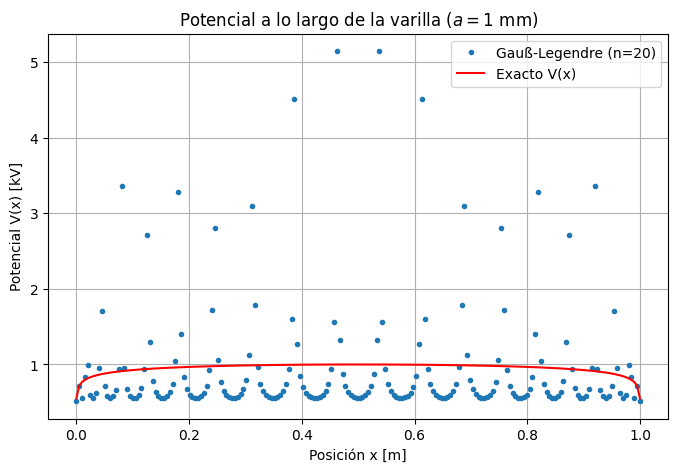


 V(L/2) numérico = 0.5554 kV

 V(L) numérico   = 0.5130 kV

 V(0) numérico   = 0.5130 kV

 V(L) exacto = 0.5499 kV

 V(0) exacto = 0.5499 kV


In [49]:
# (Punto 1) Parte 1

# Parámetros
λ_u = 8.05e-9                 # C/m
a = 1e-3                      # m
cuatro_pi_eps0 = 1.1127e-10   # F/m
L = 1                         # m

A = (λ_u*L)/(2*cuatro_pi_eps0)

def d_potencial(t, x_val):
  s = 0.5*L*(t+1)
  return 1.0 / np.sqrt((x_val - s)**2 + a**2)

def V_num(x_val, n=20):
  t, w, _ = gauss_legendre(n)
  integrando = d_potencial(t, x_val)
  return A*np.sum(d_potencial(t, x_val)*w)

def V_exacto(x_val):
  factor = (λ_u)/cuatro_pi_eps0
  return factor*(np.arcsinh(x_val/a) + np.arcsinh((L-x_val)/a))

x = np.linspace(0, L, 200)

V_num_vals = np.array([V_num(x_i, n=20) for x_i in x]) / 1000.0
V_exc_vals = V_exacto(x) / 1000.0

# Gráficas
plt.figure(figsize=(8,5))
plt.plot(x, V_num_vals, 'o', label='Gauß-Legendre (n=20)', markersize=3)
plt.plot(x, V_exc_vals, 'r-', label='Exacto V(x)')
plt.xlabel('Posición x [m]')
plt.ylabel('Potencial V(x) [kV]')
plt.title('Potencial a lo largo de la varilla ($a = 1$ mm)')
plt.grid(True)
plt.legend()
plt.show()

# Reportar V(L/2) y V(0)
print(f"\n V(L/2) numérico = {V_num(L/2)/1000:.4f} kV")
print(f"\n V(L) numérico   = {V_num(L)/1000:.4f} kV")
print(f"\n V(0) numérico   = {V_num(0)/1000:.4f} kV")
print(f'\n V(L) exacto = {V_exacto(L)/1000:.4f} kV')
print(f'\n V(0) exacto = {V_exacto(0)/1000:.4f} kV')


In [45]:
# (Punto 1) Parte 2:


# Valor Exacto en x = L/2
factor_exacto = λ_u / cuatro_pi_eps0
V_exacto_L2 = factor_exacto * (2.0 * np.arcsinh(L /(2.0 * a)))


# Forma 1: intervalo [0, L] con n puntos
def integral_directa(x_val, n_total):
    t, w, _ = gauss_legendre(n_total)
    s = 0.5 * L * (t + 1.0)
    J = L/2.0
    integrand = 1.0 / np.sqrt((x_val - s)**2 + a**2)
    return factor_exacto * np.sum(J*integrand * w)


# Forma 2: Dividir la integral en [0, L/2] y [L/2, L] con n/2 puntos en cada tramo
def integral_partida(x_val, n_total):
    m = int(n_total // 2)
    t, w, _ = gauss_legendre(m)
    J = L/4.0

    # Tramo 1: [0, L/2]
    s1 = (L / 4.0)*(t+1)
    integral1 = np.sum(w*J*(1.0 / np.sqrt((x_val - s1)**2 + a**2)))

    # Tramo 2: [L/2, L]
    s2 = (L / 4.0)*(t+3)
    integral2 = np.sum(w*J*(1.0 / np.sqrt((x_val - s2)**2 + a**2)))

    return factor_exacto * (integral1 + integral2)


# Construcción de la Tabla para n = 8 y n = 32
resultados = []

for n in [8, 32]:
    # Evaluaciones
    V_dir = integral_directa(L/2.0, n)
    V_part = integral_partida(L/2.0, n)

    # Errores relativos
    err_dir = np.abs(V_dir - V_exacto_L2) / V_exacto_L2
    err_part = np.abs(V_part - V_exacto_L2) / V_exacto_L2

    resultados.append({
        'n (Puntos)': n,
        'V Directo [kV]': V_dir / 1000.0,
        'Error Rel. Directo': f"{err_dir:.2e}",
        'V Partida [kV]': V_part / 1000.0,
        'Error Rel. Partida': f"{err_part:.2e}"
    })

# Mostrar la tabla formateada
df_resultados = pd.DataFrame(resultados)
print(f"Valor Exacto V(L/2) = {V_exacto_L2 / 1000.0:.6f} kV\n")
print(df_resultados.to_string(index=False))

Valor Exacto V(L/2) = 0.999505 kV

 n (Puntos)  V Directo [kV] Error Rel. Directo  V Partida [kV] Error Rel. Partida
          8        0.428081           5.72e-01        0.602735           3.97e-01
         32        0.621921           3.78e-01        0.953979           4.55e-02


# ***Punto 2: Matriz del Sistema***

### ***Pregunta de física***
**¿Por qué $A_{ij} = A_{ji}$?** Por simetría de la Ley de Coulomb y recipropidad electrostática. La distancia entre el centro $x_i$ y cualquier carga en el segmento $j$ es idéntica a la distancia entre $x_j$ y las cargas en el segmento $i$.

**Dependencia de $|i-j|$**: La varilla es recta, 1D y dividida en segmentos iguales $h$. La distancia entre los centros de los segmentos depende solo del número de segmentos que los separan $(|x_i - x_j| = |i-j|h)$, haciendo a A una matriz simétrica.


### ***Pregunta del método numérico***
Para $i=j$, el punto de evaluación $x_i$ está dentro del propio segmento. El integrando alcanza un pico muy aguado de altura $1/a$ en $s=x_i$, el cual requiere muchos nodos de Gauß para integrarse con precisión.

A mayor $h/a$, el pico de ancho $\approx a $ se vuelve extremadamente angosto respecto al largo del intervalo $h$. Los 8 nodos de Gauß quedan muy dispersos y 'pierden' la cima del pico. Usar la fórmula exacta $2\sinh^{-1}(h/2a)$ evita estos inconvenientes.

In [62]:
# Punto 2: Matriz del sistema

# Parámetros base
L = 1.0       # m
a = 1.0e-3    # m
N = 20        # Número de segmentos

# Función para integrar un segmento j en el intervalo [s_{j-1}, s_j] pasando 'a' como parámetro
def integrar_A_ij(x_i, s_inicio, s_fin, a_val, n_puntos=8):
    # Nodos y pesos emparejados correctamente
    t, w, _ = gauss_legendre(n_puntos)

    # Cambio de variable lineal
    s = 0.5 * (t * (s_fin - s_inicio) + s_inicio + s_fin)
    J = 0.5 * (s_fin - s_inicio)

    integrando = 1.0 / np.sqrt((x_i - s)**2 + a_val**2)
    return J * np.sum(w * integrando)


# Función para calcular la matriz A según el número N de segmentos
def matriz_A(N, a_val, L_val=1.0):
    h = L_val / N
    s_extremos = np.linspace(0, L_val, N + 1)
    x_centros = 0.5 * (s_extremos[1:] + s_extremos[:-1])

    A = np.zeros((N, N))

    for i in range(N):
        x_i = x_centros[i]
        for j in range(N):
            if i == j:
                A[i, j] = 2.0 * np.arcsinh(h / (2.0 * a_val))
            else:
                s_start = s_extremos[j]
                s_end = s_extremos[j+1]
                # Le pasamos a_val explícitamente a la función de integración
                A[i, j] = integrar_A_ij(x_i, s_start, s_end, a_val)

    return A


# Comparación del térimno A_ii con valor exacto y Gauß-Legendre
for ratio in [50, 5]:
  h_prueba = ratio*a
  exacto = 2.0*np.arcsinh(h_prueba/(2.0*a))

  # Usamos Gauß-Legendre
  t, w, _ = gauss_legendre(8)
  s_prueba = 0.5*h_prueba*t
  J = 0.5*h_prueba
  valor_gauß = J*np.sum((1.0/np.sqrt((s_prueba**2 + a**2)))*w)

  error_rel = abs(valor_gauß - exacto)/exacto
  print(f"h/a = {ratio:2d} | Exacto: {exacto:.6f} | Gauss (n=8): {valor_gauß:.6f} | Error Rel: {error_rel:.2e}")

A = matriz_A(N, a, L)

# Verificar que la matriz A es simétrica
es_simetrica = np.allclose(A, A.T)
max_diff = np.max(np.abs(A - A.T))
print(f"\n¿La matriz A es simétrica? {es_simetrica} (Diferencia máxima |A - A^T|: {max_diff:.2e})")




h/a = 50 | Exacto: 7.824846 | Gauss (n=8): 5.822216 | Error Rel: 2.56e-01
h/a =  5 | Exacto: 3.294462 | Gauss (n=8): 3.291888 | Error Rel: 7.81e-04

¿La matriz A es simétrica? True (Diferencia máxima |A - A^T|: 7.77e-15)


# ***Punto 3: Eliminación Gaußiana***

### ***Pregunta de física***
La carga se acumula en los extremos $(x → 0 \ \text{y} \ x → L)$. Esto ocurre porque las cargas en el centro repelen a las demás hacia los bordes para mantener la superficie en un potencial constante $V_0$.

Si se aumenta el radio 10 veces $(a=1 \text{cm})$, la capacitancia $C$ aumenta (pasa de ≈ 8 pF a ≈ 12 pF) porque un conductor más grueso puede almacenar más carga para el mismo potencial $V_0$. Es mayor que la de la una esfera de diámetro $L$ debido a la mayor área superficial que ofrece la varilla.


### ***Pregunta del método numérico***
Al aumentar $N$, $C$ se estabiliza y converge progresivamente hacia la referencia analítica. El pivoteo parcial evita divisiones por cero o por números muy pequeños que destruyen la precisión por errores de redondeo. El costo computacional crece como $O(N^3)$ en la fase de eliminación y $O(N^2)$ en la sustitución regresiva.

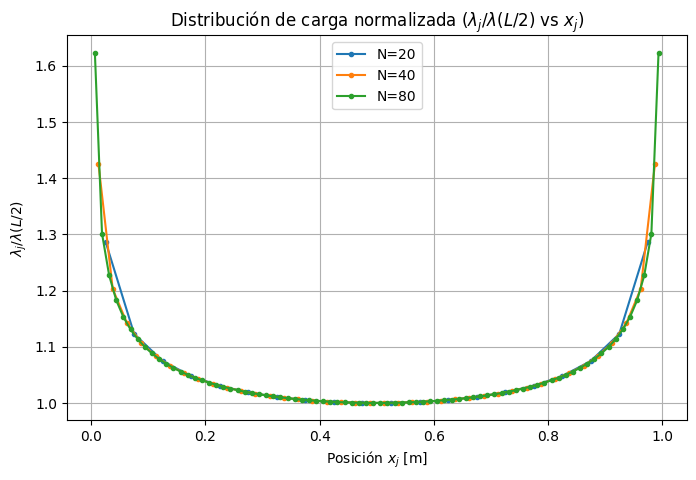


--- TABLA DE RESULTADOS PARA a = 1 mm ---
 N  C Numérica [pF]  C Ref. [pF] Error Relativo Diff vs np.solve
20         8.441526     8.457619       1.90e-03         5.55e-17
40         8.461382     8.457619       4.45e-04         6.94e-17
80         8.474121     8.457619       1.95e-03         1.39e-16

--- CÁLCULO ADICIONAL PARA a = 1 cm (N = 20) ---
Capacitancia C (a = 1 cm) = 13.0577 pF
Capacitancia C Ref. (3)   = 13.0407 pF
Capacitancia Esfera D=L   = 55.6350 pF


In [67]:
# Punto 3: Eliminación Gaußiana
A = np.array(A)                   # Matriz de coeficientes construida en el punto 2

# Capacitancia de referencia análitica dada en el taller (Ecuación (3))
def C_referencia(a, L=1.0):

  Lambda = np.log(L/a)
  termino_1 = 1.0
  termino_2 = (1.0 - np.log(2.0)) / Lambda
  termino_3 = (1.0 + (1.0 - np.log(2.0))**2 - (np.pi**2 /12.0)) / (Lambda**2)

  return (cuatro_pi_eps0*L/(2.0*Lambda))*(termino_1 + termino_2 + termino_3)


# Resolvemos para a = 1 mm y N = 20, 40, 80
L = 1.0
a = 1e-3

C_ref_1mm = C_referencia(a)
resultados = []

plt.figure(figsize=(8,5))

for N_seg in [20, 40, 80]:
  h = L/N_seg

  # Matriz y vector b (todas las entradas 1)
  A = matriz_A(N_seg, a, L)
  b = np.ones(N_seg)

  # Puntos medio x_j
  s_extremos = np.linspace(0, L, N_seg+1)
  x_centros = 0.5*(s_extremos[1:] + s_extremos[:-1])

  q = eliminacion_gaußiana(A, b)
  q_real = np.linalg.solve(A, b)
  diff_max = np.max(np.abs(q - q_real))

  # Normalizamos respecto al centro x = L/2
  idx_centro = N_seg // 2
  q_norm = q/ q[idx_centro]

  # Gráfica
  plt.plot(x_centros, q_norm, 'o-', label=f'N={N_seg}', markersize=3)

  # Capacitancia C en pF
  C_num = cuatro_pi_eps0*h*np.sum(q)
  error_rel = np.abs(C_num - C_ref_1mm)/C_ref_1mm

  resultados.append({
        'N': N_seg,
        'C Numérica [pF]': C_num * 1e12,
        'C Ref. [pF]': C_ref_1mm * 1e12,
        'Error Relativo': f"{error_rel:.2e}",
        'Diff vs np.solve': f"{diff_max:.2e}"
    })


plt.xlabel('Posición $x_j$ [m]')
plt.ylabel(r'$\lambda_j / \lambda(L/2)$')
plt.title(r'Distribución de carga normalizada ($\lambda_j / \lambda(L/2)$ vs $x_j$)')
plt.legend()
plt.grid(True)
plt.show()


print("\n--- TABLA DE RESULTADOS PARA a = 1 mm ---")
df_tabla = pd.DataFrame(resultados)
print(df_tabla.to_string(index=False))

# Cálculo adicional para a = 1.0 cm y N = 20
a_1cm = 1.0e-2
A_1cm = matriz_A(20, a_1cm, L)
q_1cm = eliminacion_gaußiana(A_1cm, np.ones(20))
C_1cm = cuatro_pi_eps0 * (L / 20.0) * np.sum(q_1cm)
C_ref_1cm = C_referencia(a_1cm)
C_esfera = 2.0 * np.pi * cuatro_pi_eps0 * L / (4.0 * np.pi) * 2.0  # 2*pi*eps0*L

print("\n--- CÁLCULO ADICIONAL PARA a = 1 cm (N = 20) ---")
print(f"Capacitancia C (a = 1 cm) = {C_1cm * 1e12:.4f} pF")
print(f"Capacitancia C Ref. (3)   = {C_ref_1cm * 1e12:.4f} pF")
print(f"Capacitancia Esfera D=L   = {2.0 * np.pi * (cuatro_pi_eps0 / (4*np.pi)) * L * 1e12:.4f} pF")

# ***Punto 4: Método de Jacobi***

### ***Pregunta de física***

### ***Pregunta del método numérico***

In [ ]:
# Punto 4: Método de Jacobi

# ***Punto 5: Refinamiento excesivo***

### ***Pregunta de física***

### ***Pregunta del método numérico***

In [ ]:
# Punto 5: Refinamiento excesivo